# ANALISIS DATA MINING FP-GROWTH — PT. SINAR SURYA MATAHARI (SSM MOTOR)
**Kerangka Kerja:** CRISP-DM (*Cross-Industry Standard Process for Data Mining*)  
**Metode:** *Multi-Attribute Association Rule Mining*  
**Dataset:** 3.113 Transaksi Y-DMS PT. Sinar Surya Matahari (Periode Operasional 2024)  
**Pembagian Pengerjaan Bab IV:**
* **4.1 Pemahaman Data (Data Understanding)**
* **4.2 Pra-Pemrosesan Data (Data Preparation) — Wahyu**
* **4.3 Pemodelan FP-Growth (Modeling) — Megi**
* **4.4 Validasi Tri-Metrik & Rekomendasi Manajerial**


In [1]:
# ==========================================
# 0. IMPORT PUSTAKA UTAMA
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Pustaka Association Rule Mining
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth, association_rules

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10
print('Pustaka berhasil dimuat!')


: 

---
## SUB-BAB 4.1: HASIL PEMAHAMAN DATA (DATA UNDERSTANDING)
Bagian ini memuat pemuatan dataset riil, pengecekan metadata awal, dan visualisasi distribusi frekuensi univariat 5 dimensi keputusan pembelian.


In [ ]:
# ==========================================
# 4.1.1 MEMUAT DATASET TRANSAKSI Y-DMS
# ==========================================
import os
# Deteksi path dataset secara dinamis (fleksibel jika dijalankan dari root maupun folder notebooks)
possible_paths = [
    os.path.join('..', 'datasets', '01_DATASET_UTAMA_DIGUNAKAN', 'data_transaksi_dealer_jun_agst_2026_clean.csv'),
    os.path.join('datasets', '01_DATASET_UTAMA_DIGUNAKAN', 'data_transaksi_dealer_jun_agst_2026_clean.csv'),
    r'D:\MATERI SLIDE\MATERI SMT 5\TUGAS SMT 5\Penelitian SI\datasets\01_DATASET_UTAMA_DIGUNAKAN\data_transaksi_dealer_jun_agst_2026_clean.csv'
]
data_path = next((p for p in possible_paths if os.path.exists(p)), possible_paths[0])

# Baca dataset transaksi bersih
df_raw = pd.read_csv(data_path)

print(f'Total Baris Transaksi : {df_raw.shape[0]} baris')
print(f'Total Kolom Awal      : {df_raw.shape[1]} kolom')
print('\nStruktur Kolom Dataset:')
display(df_raw.info())
print('\n5 Baris Pertama Data Mentah Y-DMS:')
display(df_raw.head())


Total Baris Transaksi : 3113 baris
Total Kolom Awal      : 12 kolom

Struktur Kolom Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3113 entries, 0 to 3112
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   TG_FAKTUR   3113 non-null   object
 1   NO_FAKTUR   3113 non-null   object
 2   NO_PESAN    3113 non-null   object
 3   NAMA_BRG    3113 non-null   object
 4   WARNA       3113 non-null   object
 5   NMLEASE     3113 non-null   object
 6   JK_WAKTU    3113 non-null   int64 
 7   NILAI_UMK   3113 non-null   int64 
 8   NILAI_JUAL  3113 non-null   int64 
 9   KOTA        3113 non-null   object
 10  UMUR        3113 non-null   int64 
 11  NM_CABANG   3113 non-null   object
dtypes: int64(4), object(8)
memory usage: 292.0+ KB


None


5 Baris Pertama Data Mentah Y-DMS:


,TG_FAKTUR,NO_FAKTUR,NO_PESAN,NAMA_BRG,WARNA,NMLEASE,JK_WAKTU,NILAI_UMK,NILAI_JUAL,KOTA,UMUR,NM_CABANG
0,2026-06-02T00:00:00,26FJK0101925,26SO01192001,FAZZIO HYBRID,ABU PINK,BAF BHL,32,0,22470000,JAKARTA TIMUR,17,GD.SSM BEKASI
1,2026-06-02T00:00:00,26FJK0101926,26SO01192201,ALL NEW AEROX 155,HITAM,BAF BHL,23,1700000,28880000,JAKARTA TIMUR,5,GD.SSM BEKASI
2,2026-06-02T00:00:00,26FJK0101927,26SO01192301,FAZZIO HYBRID NEO,HIJAU MUDA,ADIRA BKS,20,500000,24300000,"BEKASI, KOTA.",5,GD.SSM BEKASI
3,2026-06-02T00:00:00,26FJK0101928,26SO01192401,FREEGO 125,MERAH,CASH,0,22415000,22865000,"JAKARTA SELATAN, KOTA.",28,GD.SSM BEKASI
4,2026-06-02T00:00:00,26FJK0101929,26SO01192501,FREEGO 125,MERAH,BAF BHL,33,500000,22865000,"JAKARTA UTARA, KOTA.",14,SSM MOTOR


In [ ]:
# ==========================================
# 4.1.2 EKSPLORASI STATISTIK UNIVARIAT 5 DIMENSI
# ==========================================
print('=== 1. JUMLAH MODEL MOTOR (44 MODEL) ===')
print(df_raw['NAMA_BRG'].value_counts().head(10))

print('\n=== 2. JUMLAH VARIAN WARNA (22 WARNA) ===')
print(df_raw['WARNA'].value_counts().head(10))

print('\n=== 3. LEMBAGA PEMBIAYAAN / LEASING ===')
print(df_raw['NMLEASE'].value_counts().head(10))

print('\n=== 4. TENOR CICILAN (BULAN) ===')
print(df_raw['JK_WAKTU'].value_counts())

print('\n=== 5. WILAYAH DOMISILI KONSUMEN ===')
print(df_raw['KOTA'].value_counts().head(10))


=== 1. JUMLAH MODEL MOTOR (44 MODEL) ===
NAMA_BRG
AEROX ALPHA                468
MIO M3 CW                  434
GEAR 125                   325
NMAX NEO S                 252
GRAND FILANO HYBRID NEO    211
MX KING 150                185
FAZZIO HYBRID NEO          142
FAZZIO HYBRID              117
G ULTIMA HYBRID            110
G ULTIMA HYBRID SMART       96
Name: count, dtype: int64

=== 2. JUMLAH VARIAN WARNA (22 WARNA) ===
WARNA
HITAM          1317
BIRU            349
MERAH           203
PUTIH           201
ABU-ABU         171
UNGU MUDA       138
PERAK HIJAU     109
PERAK           108
HIJAU            92
HIJAU PERAK      73
Name: count, dtype: int64

=== 3. LEMBAGA PEMBIAYAAN / LEASING ===
NMLEASE
CASH              1969
BAF BHL            380
BAF JAKARTA  2     160
BAF CKR            106
BAF CMPK            85
BAF DPK             61
ADIRA DMGT          49
ADIRA BKS           43
ADIRA TBN           40
ADIRA KLPG          36
Name: count, dtype: int64

=== 4. TENOR CICILAN (BULAN) ===


C:\Users\MyBook Hype AMD\AppData\Local\Temp\ipykernel_17228\2802814129.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_models.values, y=top_models.index, ax=axes[0, 0], palette='Blues_r')
C:\Users\MyBook Hype AMD\AppData\Local\Temp\ipykernel_17228\2802814129.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_warna.values, y=top_warna.index, ax=axes[0, 1], palette='Oranges_r')


C:\Users\MyBook Hype AMD\AppData\Local\Temp\ipykernel_17228\2802814129.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_cities.values, y=top_cities.index, ax=axes[1, 1], palette='Purples_r')


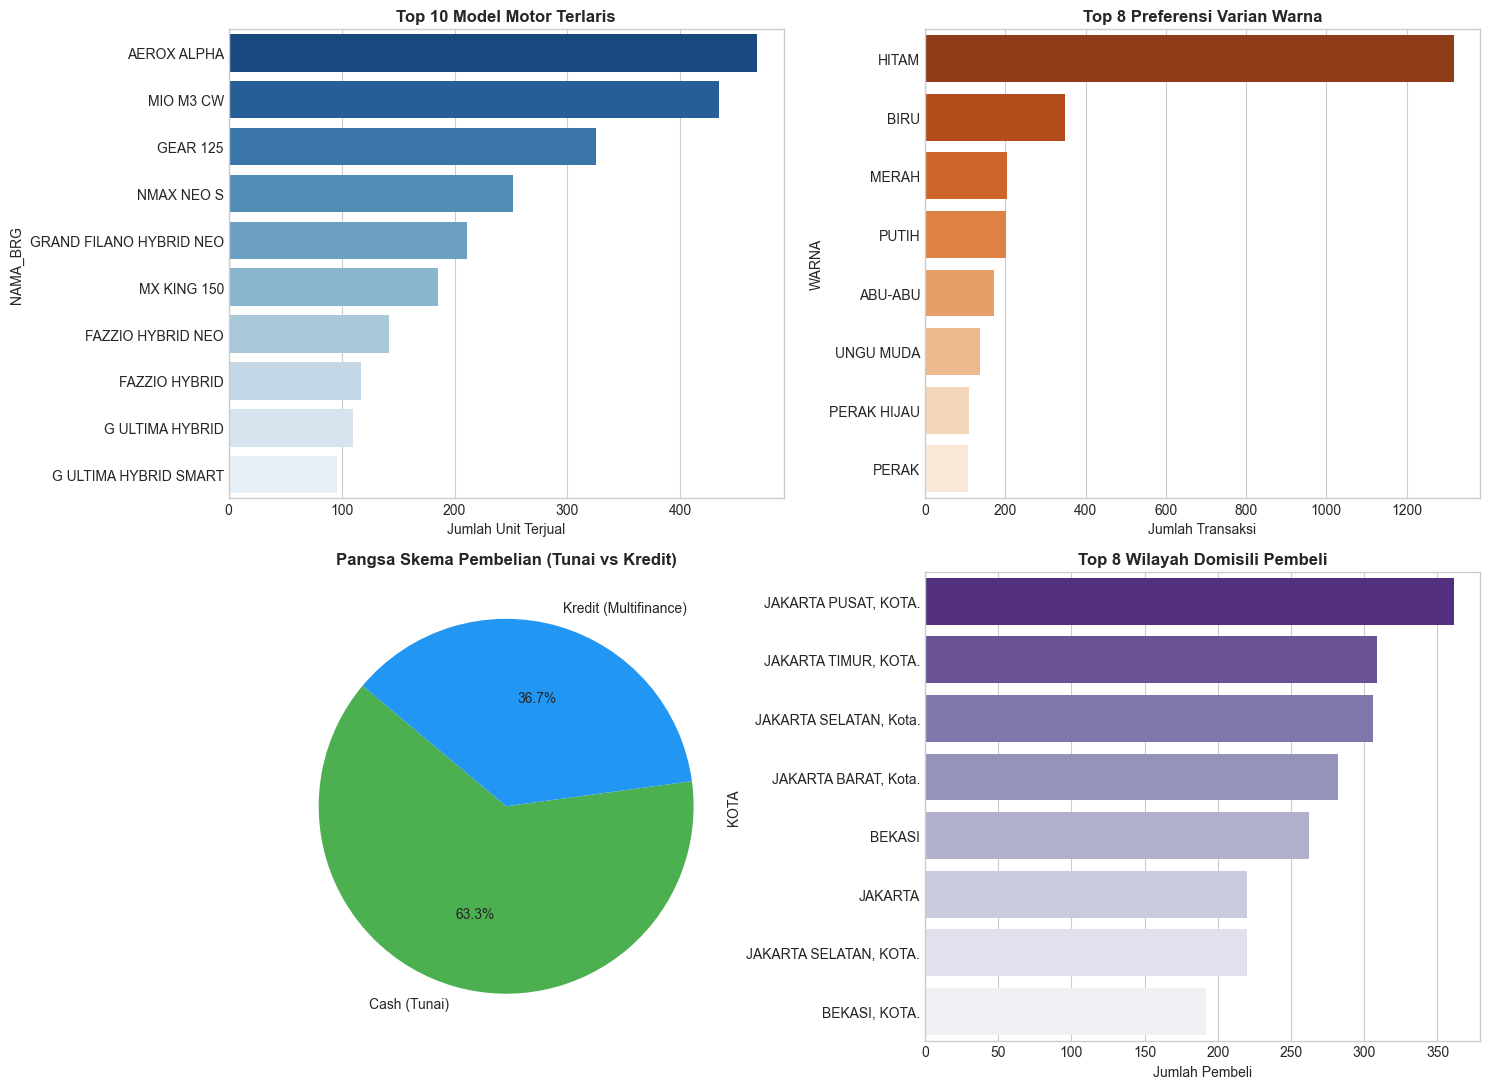

Grafik univariat berhasil disimpan: visualisasi_4_1_univariat.png


In [ ]:
# ==========================================
# VISUALISASI DISTRIBUSI FREKUENSI PENJUALAN
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Top 10 Model Terlaris
top_models = df_raw['NAMA_BRG'].value_counts().head(10)
sns.barplot(x=top_models.values, y=top_models.index, ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Top 10 Model Motor Terlaris', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Jumlah Unit Terjual')

# 2. Top 8 Warna Terfavorit
top_warna = df_raw['WARNA'].value_counts().head(8)
sns.barplot(x=top_warna.values, y=top_warna.index, ax=axes[0, 1], palette='Oranges_r')
axes[0, 1].set_title('Top 8 Preferensi Varian Warna', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Jumlah Transaksi')

# 3. Proporsi Pembelian Tunai vs Kredit
is_cash = df_raw['NMLEASE'].astype(str).str.contains('CASH').map({True: 'Cash (Tunai)', False: 'Kredit (Multifinance)'})
cash_prop = is_cash.value_counts()
axes[1, 0].pie(cash_prop.values, labels=cash_prop.index, autopct='%1.1f%%', colors=['#4CAF50', '#2196F3'], startangle=140)
axes[1, 0].set_title('Pangsa Skema Pembelian (Tunai vs Kredit)', fontsize=12, fontweight='bold')

# 4. Top 8 Wilayah Domisili Konsumen
top_cities = df_raw['KOTA'].value_counts().head(8)
sns.barplot(x=top_cities.values, y=top_cities.index, ax=axes[1, 1], palette='Purples_r')
axes[1, 1].set_title('Top 8 Wilayah Domisili Pembeli', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Jumlah Pembeli')

plt.tight_layout()
plt.savefig('visualisasi_4_1_univariat.png', dpi=300)
plt.show()
print('Grafik univariat berhasil disimpan: visualisasi_4_1_univariat.png')


---
## SUB-BAB 4.2: HASIL PRA-PEMROSESAN DAN TRANSFORMASI DATA (DATA PREPARATION) — TUGAS WAHYU
Pada bagian ini dilakukan:
1. Pembersihan & penyeragaman kategori atribut.
2. Anonimisasi atribut privasi.
3. Transformasi keranjang predikat multiatribut `{Atribut=Nilai}`.
4. Pengodean matriks biner (*One-Hot Encoding*) 3.113 baris x 87 kolom.


In [ ]:
# ==========================================
# 4.2.1 STANDARDISASI & ANONYMIZATION
# ==========================================
df_clean = df_raw.copy()

# Fungsi standarisasi leasing
def map_leasing(val):
    val = str(val).upper().strip()
    if 'CASH' in val: return 'Cash'
    if 'BAF' in val: return 'BAF'
    if 'ADIRA' in val or 'ADR' in val: return 'Adira'
    if 'OTO' in val: return 'OTO'
    return 'Lainnya'

# Fungsi standarisasi wilayah domisili
def map_wilayah(val):
    val = str(val).upper().strip()
    if 'BEKASI, KAB' in val or 'BEKASI, Kab' in val: return 'Kab. Bekasi'
    if 'BEKASI' in val: return 'Kota Bekasi'
    if 'JAKARTA TIMUR' in val: return 'Jakarta Timur'
    if 'JAKARTA SELATAN' in val: return 'Jakarta Selatan'
    if 'JAKARTA PUSAT' in val: return 'Jakarta Pusat'
    if 'JAKARTA BARAT' in val: return 'Jakarta Barat'
    if 'JAKARTA UTARA' in val: return 'Jakarta Utara'
    if 'DEPOK' in val: return 'Depok'
    if 'BOGOR' in val: return 'Bogor'
    if 'TANGERANG' in val: return 'Tangerang'
    return 'Area Lain'

# Fungsi standarisasi tenor angsuran
def map_tenor(val):
    try:
        t = int(val)
        if t == 0: return 'Non-Kredit'
        if t >= 34: return 'Tenor 35 Bln'
        if t >= 29: return 'Tenor 30-32 Bln'
        if t >= 20: return 'Tenor 20-23 Bln'
        return 'Tenor 11-17 Bln'
    except:
        return 'Non-Kredit'

# Terapkan pemetaan
df_clean['LEASING_STD'] = df_clean['NMLEASE'].apply(map_leasing)
df_clean['WILAYAH_STD'] = df_clean['KOTA'].apply(map_wilayah)
df_clean['TENOR_STD'] = df_clean['JK_WAKTU'].apply(map_tenor)

# Anonimisasi: Ambil hanya 5 kolom atribut keputusan pembelian
df_features = df_clean[['NAMA_BRG', 'WARNA', 'LEASING_STD', 'TENOR_STD', 'WILAYAH_STD']].copy()
df_features.columns = ['Model', 'Warna', 'Leasing', 'Tenor', 'Wilayah']

print('Contoh 5 Baris Fitur Keputusan Pembelian Pasca-Anonimisasi:')
display(df_features.head())


Contoh 5 Baris Fitur Keputusan Pembelian Pasca-Anonimisasi:


,Model,Warna,Leasing,Tenor,Wilayah
0,FAZZIO HYBRID,ABU PINK,BAF,Tenor 30-32 Bln,Jakarta Timur
1,ALL NEW AEROX 155,HITAM,BAF,Tenor 20-23 Bln,Jakarta Timur
2,FAZZIO HYBRID NEO,HIJAU MUDA,Adira,Tenor 20-23 Bln,Kota Bekasi
3,FREEGO 125,MERAH,Cash,Non-Kredit,Jakarta Selatan
4,FREEGO 125,MERAH,BAF,Tenor 30-32 Bln,Jakarta Utara


In [ ]:
# ==========================================
# 4.2.2 TRANSFORMASI KERANJANG PREDIKAT MULTIATRIBUT
# ==========================================
basket_transactions = []

for _, row in df_features.iterrows():
    basket = [
        f"Model={str(row['Model']).strip()}",
        f"Warna={str(row['Warna']).strip()}",
        f"Leasing={str(row['Leasing'])}",
        f"Tenor={str(row['Tenor'])}",
        f"Wilayah={str(row['Wilayah'])}"
    ]
    basket_transactions.append(basket)

print(f'Total Transaksi Keranjang: {len(basket_transactions)}')
print('\nContoh 5 Keranjang Predikat Multiatribut:')
for i in range(5):
    print(f'TRX-{i+1:04d}: {basket_transactions[i]}')


Total Transaksi Keranjang: 3113

Contoh 5 Keranjang Predikat Multiatribut:
TRX-0001: ['Model=FAZZIO HYBRID', 'Warna=ABU PINK', 'Leasing=BAF', 'Tenor=Tenor 30-32 Bln', 'Wilayah=Jakarta Timur']
TRX-0002: ['Model=ALL NEW AEROX 155', 'Warna=HITAM', 'Leasing=BAF', 'Tenor=Tenor 20-23 Bln', 'Wilayah=Jakarta Timur']
TRX-0003: ['Model=FAZZIO HYBRID NEO', 'Warna=HIJAU MUDA', 'Leasing=Adira', 'Tenor=Tenor 20-23 Bln', 'Wilayah=Kota Bekasi']
TRX-0004: ['Model=FREEGO 125', 'Warna=MERAH', 'Leasing=Cash', 'Tenor=Non-Kredit', 'Wilayah=Jakarta Selatan']
TRX-0005: ['Model=FREEGO 125', 'Warna=MERAH', 'Leasing=BAF', 'Tenor=Tenor 30-32 Bln', 'Wilayah=Jakarta Utara']


In [ ]:
# ==========================================
# 4.2.3 PEMBENTUKAN MATRIKS INSIDENSI BINER
# ==========================================
te = TransactionEncoder()
te_ary = te.fit(basket_transactions).transform(basket_transactions)
df_binary = pd.DataFrame(te_ary, columns=te.columns_)

print(f'Dimensi Matriks Biner Akhir: {df_binary.shape[0]} Baris x {df_binary.shape[1]} Kolom Predikat')
print('\nCuplikan 5 Baris Pertama Matriks Insidensi Biner (10 Kolom Pertama):')
display(df_binary.iloc[:5, :10])


Dimensi Matriks Biner Akhir: 3113 Baris x 87 Kolom Predikat

Cuplikan 5 Baris Pertama Matriks Insidensi Biner (10 Kolom Pertama):


,Leasing=Adira,Leasing=BAF,Leasing=Cash,Leasing=Lainnya,Leasing=OTO,Model=AEROX ALPHA,Model=AEROX ALPHA -TURBO-,Model=AEROX ALPHA CYBERCITY,Model=AEROX ALPHA CYBERCITY ABS,Model=AEROX ALPHA-TURBO- 70TH LIVERY
0,False,True,False,False,False,False,False,False,False,False
1,False,True,False,False,False,False,False,False,False,False
2,True,False,False,False,False,False,False,False,False,False
3,False,False,True,False,False,False,False,False,False,False
4,False,True,False,False,False,False,False,False,False,False


---
## SUB-BAB 4.3: HASIL PEMODELAN KOMPUTASI FP-GROWTH (MODELING) — TUGAS MEGI
Pada bagian ini dilakukan:
1. Pembangkitan F-List (Urutan itemset frekuensi tinggi).
2. Eksekusi algoritma FP-Growth dengan *Minimum Support*.
3. Rekapitulasi jumlah *k-itemset* yang terbentuk.
4. Pembangkitan kaidah asosiasi dan validasi Tri-Metrik (*Support*, *Confidence*, dan *Lift Ratio* > 1,0).


In [ ]:
# ==========================================
# 4.3.1 PEMBENTUKAN FREQUENT ITEMSETS (FP-GROWTH)
# ==========================================
# Tetapkan parameter Minimum Support (2% atau 0.02)
min_sup = 0.02

# Jalankan algoritma FP-Growth
frequent_itemsets = fpgrowth(df_binary, min_support=min_sup, use_colnames=True)
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(lambda x: len(x))
frequent_itemsets = frequent_itemsets.sort_values(by='support', ascending=False).reset_index(drop=True)

print(f'Total Frequent Itemsets yang Lolos (min_support={min_sup*100}%): {len(frequent_itemsets)}')
print('\nRekapitulasi Jumlah Itemset Berdasarkan Panjang Kombinasi (k-itemset):')
display(frequent_itemsets['length'].value_counts().sort_index().rename('Jumlah Pola'))

print('\nTop 15 Frequent Itemsets Tertinggi:')
display(frequent_itemsets.head(15))


Total Frequent Itemsets yang Lolos (min_support=2.0%): 259

Rekapitulasi Jumlah Itemset Berdasarkan Panjang Kombinasi (k-itemset):


length
1     39
2    105
3     78
4     32
5      5
Name: Jumlah Pola, dtype: int64


Top 15 Frequent Itemsets Tertinggi:


,support,itemsets,length
0,0.632509,(Tenor=Non-Kredit),1
1,0.632509,"(Tenor=Non-Kredit, Leasing=Cash)",2
2,0.632509,(Leasing=Cash),1
3,0.423065,(Warna=HITAM),1
4,0.306778,"(Warna=HITAM, Tenor=Non-Kredit, Leasing=Cash)",3
5,0.306778,"(Warna=HITAM, Leasing=Cash)",2
6,0.306778,"(Warna=HITAM, Tenor=Non-Kredit)",2
7,0.271121,(Leasing=BAF),1
8,0.202698,(Tenor=Tenor 30-32 Bln),1
9,0.175394,(Wilayah=Jakarta Selatan),1


In [ ]:
# ==========================================
# 4.3.2 PEMBENTUKAN KAIDAH ASOSIASI & VALIDASI TRI-METRIK
# ==========================================
# Batas Minimum Confidence (50% atau 0.50)
min_conf = 0.50

# Pembangkitan kaidah asosiasi
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=min_conf)

# Filter ilmiah: Hanya pertahankan kaidah dengan Lift Ratio > 1.0 (korelasi positif murni)
valid_rules = rules[rules['lift'] > 1.0].sort_values(by='lift', ascending=False).reset_index(drop=True)

print(f'Total Kaidah Asosiasi Mentah (Confidence >= {min_conf*100}%): {len(rules)}')
print(f'Total Kaidah Lolos Validasi Ilmiah (Lift Ratio > 1.0)        : {len(valid_rules)}')

# Format tabel top 15 rules untuk Bab IV
top_15_rules = valid_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(15).copy()
top_15_rules['antecedents'] = top_15_rules['antecedents'].apply(lambda x: ', '.join(list(x)))
top_15_rules['consequents'] = top_15_rules['consequents'].apply(lambda x: ', '.join(list(x)))
top_15_rules['support'] = (top_15_rules['support'] * 100).round(2).astype(str) + '%'
top_15_rules['confidence'] = (top_15_rules['confidence'] * 100).round(2).astype(str) + '%'
top_15_rules['lift'] = top_15_rules['lift'].round(3)

print('\n=== TABEL 4.5: TOP 15 KAIDAH ASOSIASI TERBAIK HASIL VALIDASI TRI-METRIK ===')
display(top_15_rules)

# Ekspor ke file CSV agar Wahyu dan Megi bisa langsung copy ke Word
csv_output = 'top_15_association_rules_ssm_motor.csv'
top_15_rules.to_csv(csv_output, index=False)
print(f'\nFile CSV hasil aturan berhasil disimpan di: {csv_output}')


Total Kaidah Asosiasi Mentah (Confidence >= 50.0%): 399
Total Kaidah Lolos Validasi Ilmiah (Lift Ratio > 1.0)        : 396

=== TABEL 4.5: TOP 15 KAIDAH ASOSIASI TERBAIK HASIL VALIDASI TRI-METRIK ===


,antecedents,consequents,support,confidence,lift
0,"Tenor=Non-Kredit, Leasing=Cash, Warna=HIJAU PERAK",Model=GEAR 125,2.35%,100.0%,9.578
1,"Tenor=Non-Kredit, Warna=HIJAU PERAK","Leasing=Cash, Model=GEAR 125",2.35%,100.0%,9.578
2,"Leasing=Cash, Warna=HIJAU PERAK","Tenor=Non-Kredit, Model=GEAR 125",2.35%,100.0%,9.578
3,Warna=HIJAU PERAK,"Tenor=Non-Kredit, Leasing=Cash, Model=GEAR 125",2.35%,100.0%,9.578
4,"Leasing=Cash, Warna=HIJAU PERAK",Model=GEAR 125,2.35%,100.0%,9.578
5,Warna=HIJAU PERAK,Model=GEAR 125,2.35%,100.0%,9.578
6,Warna=HIJAU PERAK,"Tenor=Non-Kredit, Model=GEAR 125",2.35%,100.0%,9.578
7,"Tenor=Non-Kredit, Warna=HIJAU PERAK",Model=GEAR 125,2.35%,100.0%,9.578
8,Warna=HIJAU PERAK,"Leasing=Cash, Model=GEAR 125",2.35%,100.0%,9.578
9,Warna=UNGU MUDA,Model=GRAND FILANO HYBRID NEO,2.76%,62.32%,9.194



File CSV hasil aturan berhasil disimpan di: D:\MATERI SLIDE\MATERI SMT 5\TUGAS SMT 5\Penelitian SI\top_15_association_rules_ssm_motor.csv


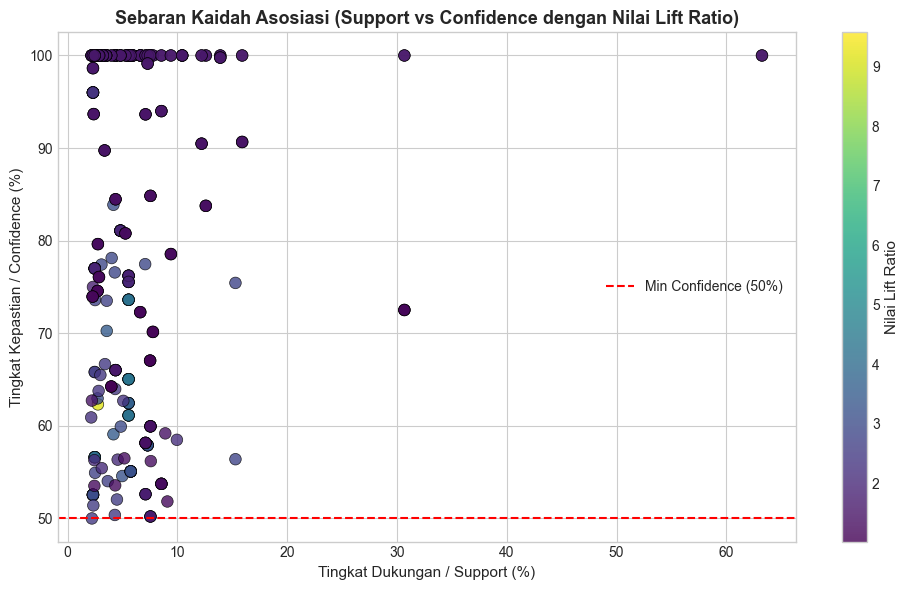

Grafik evaluasi berhasil disimpan: visualisasi_4_4_scatter_rules.png


In [ ]:
# ==========================================
# VISUALISASI SEBARAN KAIDAH ASOSIASI (SCATTER PLOT)
# ==========================================
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    valid_rules['support'] * 100, 
    valid_rules['confidence'] * 100, 
    c=valid_rules['lift'], 
    cmap='viridis', 
    s=70, 
    alpha=0.8, 
    edgecolors='black', 
    linewidth=0.5
)
cbar = plt.colorbar(scatter)
cbar.set_label('Nilai Lift Ratio', fontsize=11)

plt.title('Sebaran Kaidah Asosiasi (Support vs Confidence dengan Nilai Lift Ratio)', fontsize=13, fontweight='bold')
plt.xlabel('Tingkat Dukungan / Support (%)', fontsize=11)
plt.ylabel('Tingkat Kepastian / Confidence (%)', fontsize=11)
plt.axhline(y=50, color='r', linestyle='--', label='Min Confidence (50%)')
plt.legend()
plt.tight_layout()
plt.savefig('visualisasi_4_4_scatter_rules.png', dpi=300)
plt.show()
print('Grafik evaluasi berhasil disimpan: visualisasi_4_4_scatter_rules.png')
